In [1]:
import numpy as np
import os
import cv2
from tqdm import tqdm
from pynwb import NWBHDF5IO
import spikeinterface.full as si
import spikeinterface.extractors as se


file_path= "/Users/Zita/Documents/EGYETEM/Önlab/yolo26/Rat01_Insertion2_Depth2.nwb"
sorting = si.read_nwb_sorting("/Users/Zita/Documents/EGYETEM/Önlab/yolo26/Rat01_Insertion2_Depth2.nwb")

io = NWBHDF5IO(file_path, "r")
nwb = io.read()
units_df = nwb.units.to_dataframe()
es = list(nwb.acquisition.values())[0]
print("conversion:", es.conversion)
print("offset:", es.offset)
print("unit:", es.unit)
print("resolution:", es.resolution)
io.close()


recording=si.read_nwb(file_path)

recording.set_channel_gains([0.195] * recording.get_num_channels())

recording_bp=si.bandpass_filter(recording, 300,3000)
recording_cmr=si.common_reference(recording_bp,reference= "global", operator="median", )
recording_preprocessed=si.whiten(recording_cmr, dtype="float32")
total_frames = recording.get_num_frames()
fs = recording.get_sampling_frequency()
num_channels = recording.get_num_channels()
num_frames = recording.get_num_frames()
duration = total_frames / fs

print(f"Sampling frequency : {fs:.0f} Hz")
print(f"Channels           : {num_channels}")
print(f"Frames             : {total_frames}")
print(f"Duration           : {duration:.1f} s")



conversion: 0.195
offset: 0.0
unit: volts
resolution: 0.195
Sampling frequency : 20000 Hz
Channels           : 128
Frames             : 47854800
Duration           : 2392.7 s


In [ ]:
spike_idx = len(events) // 4
spike_frame = int(events[spike_idx, 0])
spike_channel = int(events[spike_idx, 2])
window_half = int(fs * 0.002)

fig, axes = plt.subplots(len(stages), 1, figsize=(8, 8), sharex=True)

for ax, (name, rec) in zip(axes, stages.items()):
    seg = rec.get_traces(start_frame=spike_frame - window_half, end_frame=spike_frame + window_half,
                          return_in_uV=(name != "Whitened"))
    t = (np.arange(seg.shape[0]) - window_half) / fs * 1000
    x = seg[:, spike_channel]

    ax.plot(t, x, color="black", linewidth=1.0)
    ax.axvline(0, color="0.6", linestyle="--", linewidth=0.8)
    ax.set_ylabel(name, rotation=0, labelpad=45, va="center")
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

axes[-1].set_xlabel("time (ms)")
fig.suptitle(f"Single spike (frame {spike_frame}, channel {spike_channel}) through preprocessing", y=1.02)
plt.tight_layout()
plt.savefig("single_spike_preprocessingtest.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Parameters
channel = 64          # Choose channel
start_time = 10       # seconds
duration = 2          # seconds

fs = recording.get_sampling_frequency()

start_frame = int(start_time * fs)
end_frame = int((start_time + duration) * fs)

# Extract raw trace
trace = recording.get_traces(
    start_frame=start_frame,
    end_frame=end_frame,
    channel_ids=[recording.channel_ids[channel]]
).squeeze()

# Time axis
time = np.arange(len(trace)) / fs + start_time

# Plot
plt.figure(figsize=(14, 4))
plt.plot(time, trace, linewidth=0.5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (µV)")
plt.title(f"Raw recording – Channel {channel} ({duration} s)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "multichannel_recording.png",
    dpi=300
)
plt.show()

In [ ]:
white = recording_whitened.get_traces(
    start_frame=start,
    end_frame=end,
    channel_ids=recording.channel_ids[channels]
).T

plt.figure(figsize=(7,6))

plt.imshow(
    white,
    aspect="auto",
    origin="lower",
    cmap="RdBu_r",
    extent=[time[0], time[-1], channels[0], channels[-1]]
)

plt.colorbar(label="Amplitude")

plt.xlabel("Time (ms)")
plt.ylabel("Channel")

plt.title("Bandpass + CMR + Whitening")
plt.savefig(
    "multichannel_spike_whitened.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# Parameters
# -------------------------

unit_id = sorting.unit_ids[0]      # neuron to inspect
channel = 64                       # channel to display

window_ms = 4                      # ±2 ms
half_window = int(window_ms / 1000 * fs / 2)

# choose a few spikes
spike_indices = [50, 100, 200, 300, 400]

recordings = [
    ("Raw", recording),
    ("Bandpass", recording_bandpassed),
    ("Bandpass + CMR", recording_referenced),
    ("Bandpass + CMR + Whitening", recording_whitened),
]

spike_train = sorting.get_unit_spike_train(unit_id)

for spike_number in spike_indices:

    center = spike_train[spike_number]

    start = center - half_window
    end = center + half_window

    fig, axes = plt.subplots(
        4, 1,
        figsize=(8,8),
        sharex=True
    )

    for ax, (title, rec) in zip(axes, recordings):

        trace = rec.get_traces(
            start_frame=start,
            end_frame=end,
            channel_ids=[recording.channel_ids[channel]]
        ).squeeze()

        time = (
            np.arange(len(trace)) - len(trace)/2
        ) / fs * 1000

        ax.plot(time, trace)

        ax.axvline(0, color="red", ls="--")

        ax.set_title(title)
        ax.grid(alpha=0.3)

    axes[-1].set_xlabel("Time (ms)")

    plt.suptitle(f"Spike {spike_number}  (Unit {unit_id})")

    plt.tight_layout()
    plt.savefig(
        f"spike_{spike_number}_unit_{unit_id}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

Rendering macroscopic continuous signal evaluation (Voltage)...


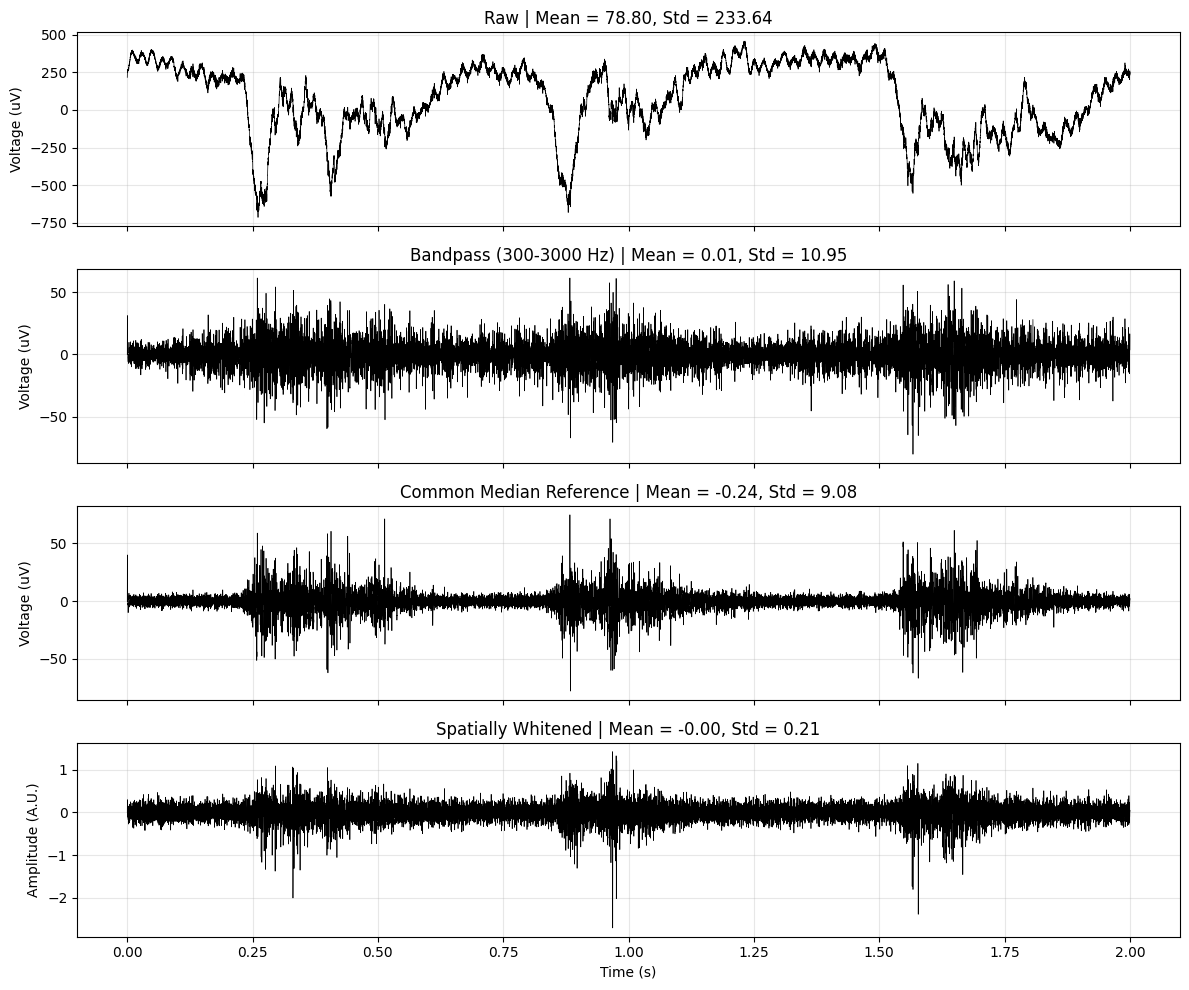


Minimum voltage deflection detected at frame 31008 on channel 55.
Rendering microscopic spike evaluation (Voltage)...


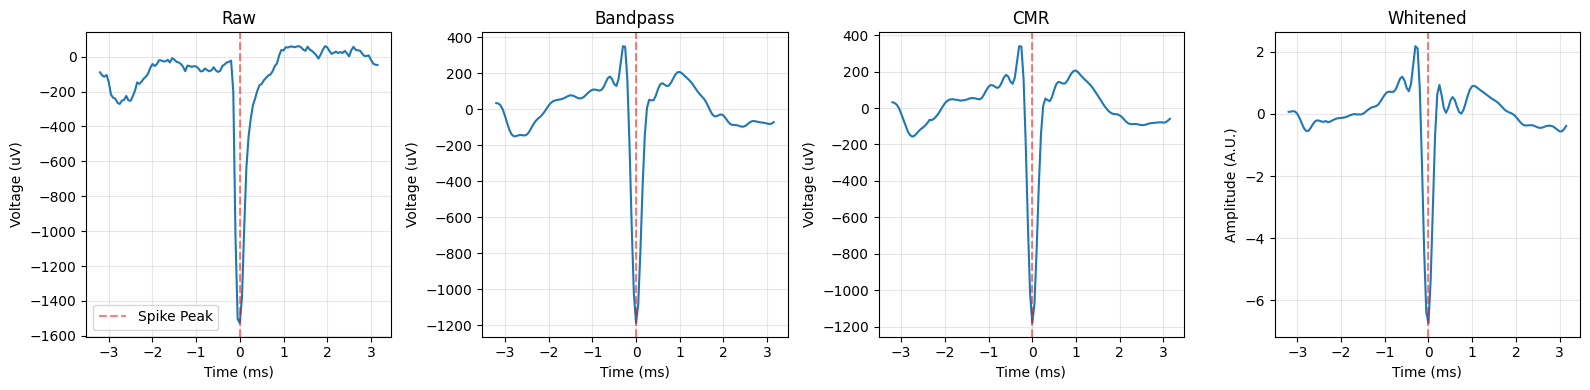

In [3]:
import matplotlib.pyplot as plt
import numpy as np

def plot_macroscopic_preprocessing_voltage(raw, bp, cmr, whitened, start_frame, end_frame, channel_idx=0):
    """
    Visualizes continuous signal variance and artifact attenuation.
    Extracts physical voltage (uV) for applicable preprocessing stages.
    """
    fs = raw.get_sampling_frequency()
    time_sec = np.arange(start_frame, end_frame) / fs
    
    fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
    
    stages = [
        (raw, "Raw"),
        (bp, "Bandpass (300-3000 Hz)"),
        (cmr, "Common Median Reference"),
        (whitened, "Spatially Whitened")
    ]
    
    for i, (rec, title) in enumerate(stages):
        # Force extraction in physical units. Whitened object bypasses this flag inherently.
        trace = rec.get_traces(
            start_frame=start_frame, 
            end_frame=end_frame, 
            return_in_uV=True
        )[:, channel_idx]
        
        axes[i].plot(time_sec, trace, color='black', linewidth=0.5)
        
        mu = np.mean(trace)
        sigma = np.std(trace)
        axes[i].set_title(f"{title} | Mean = {mu:.2f}, Std = {sigma:.2f}")
        
        ylabel = "Voltage (uV)" if i < 3 else "Amplitude (A.U.)"
        axes[i].set_ylabel(ylabel)
        axes[i].grid(True, alpha=0.3)
        
    axes[-1].set_xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

def plot_microscopic_spike_voltage(raw, bp, cmr, whitened, peak_frame, window_size=128, channel_idx=0):
    """
    Visualizes the structural morphology of a localized action potential.
    Extracts physical voltage (uV) for applicable preprocessing stages.
    """
    fs = raw.get_sampling_frequency()
    start = peak_frame - (window_size // 2)
    end = peak_frame + (window_size // 2)
    
    time_ms = (np.arange(window_size) - (window_size // 2)) * (1000.0 / fs)
    
    fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=False)
    
    stages = [
        (raw, "Raw"),
        (bp, "Bandpass"),
        (cmr, "CMR"),
        (whitened, "Whitened")
    ]
    
    for i, (rec, title) in enumerate(stages):
        trace = rec.get_traces(
            start_frame=start, 
            end_frame=end, 
            return_in_uV=True
        )[:, channel_idx]
        
        axes[i].plot(time_ms, trace, color='#1f77b4', linewidth=1.5)
        axes[i].axvline(x=0, color='red', linestyle='--', alpha=0.5, label='Spike Peak')
        
        axes[i].set_title(title)
        axes[i].set_xlabel("Time (ms)")
        axes[i].grid(True, alpha=0.3)
        
        ylabel = "Voltage (uV)" if i < 3 else "Amplitude (A.U.)"
        axes[i].set_ylabel(ylabel)
        
    axes[0].legend()
    plt.tight_layout()
    plt.show()

# Parameters for Macroscopic Evaluation
target_channel = 0
frame_start = 0
frame_end = int(2.0 * fs)

print("Rendering macroscopic continuous signal evaluation (Voltage)...")
plot_macroscopic_preprocessing_voltage(
    raw=recording,
    bp=recording_bp,
    cmr=recording_cmr,
    whitened=recording_preprocessed,
    start_frame=frame_start,
    end_frame=frame_end,
    channel_idx=target_channel
)

# Parameters for Microscopic Evaluation
search_frames = int(5.0 * fs)

# Search within the CMR object to identify a physical biological deflection
cmr_search_chunk = recording_cmr.get_traces(
    start_frame=0, 
    end_frame=search_frames, 
    return_in_uV=True
)

# Isolate absolute minimum voltage (peak extracellular action potential)
flat_peak_idx = np.argmin(cmr_search_chunk)
target_spike_frame, target_spike_channel = np.unravel_index(flat_peak_idx, cmr_search_chunk.shape)

print(f"\nMinimum voltage deflection detected at frame {target_spike_frame} on channel {target_spike_channel}.")
print("Rendering microscopic spike evaluation (Voltage)...")

plot_microscopic_spike_voltage(
    raw=recording,
    bp=recording_bp,
    cmr=recording_cmr,
    whitened=recording_preprocessed,
    peak_frame=target_spike_frame,
    window_size=128,
    channel_idx=target_spike_channel
)

Executing spatial neighborhood analysis on distributed events...


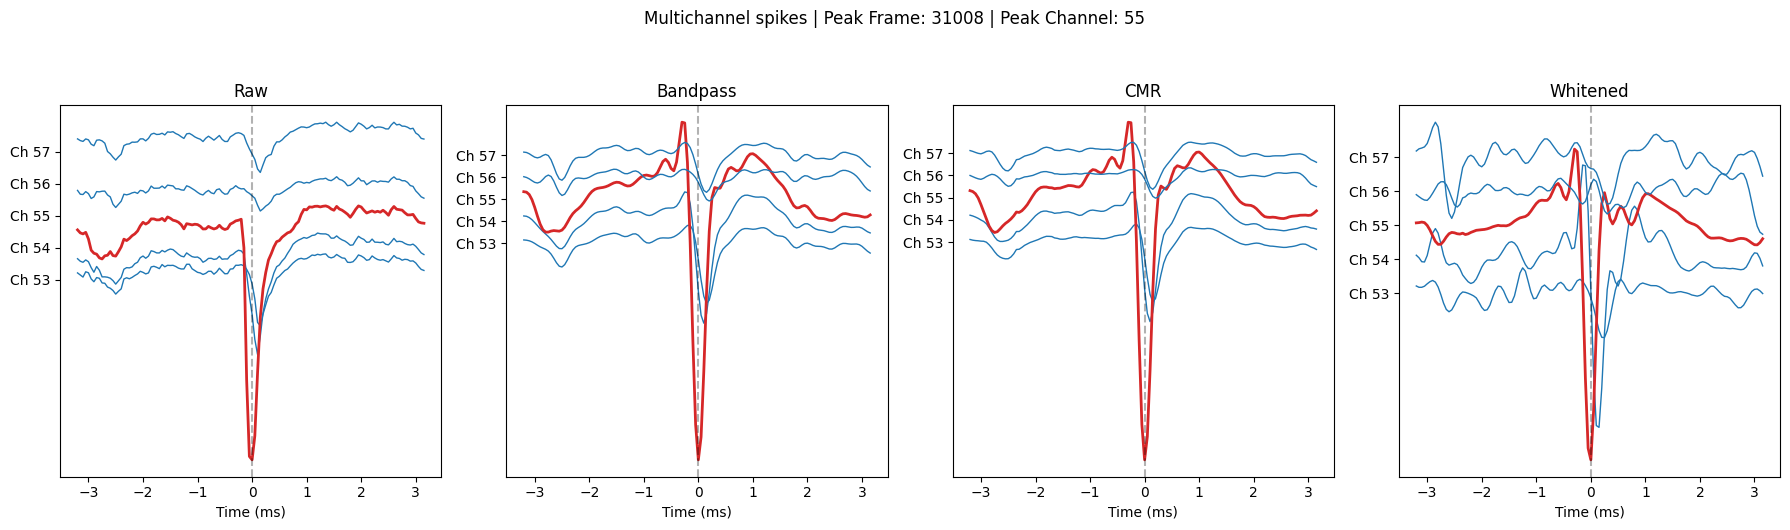

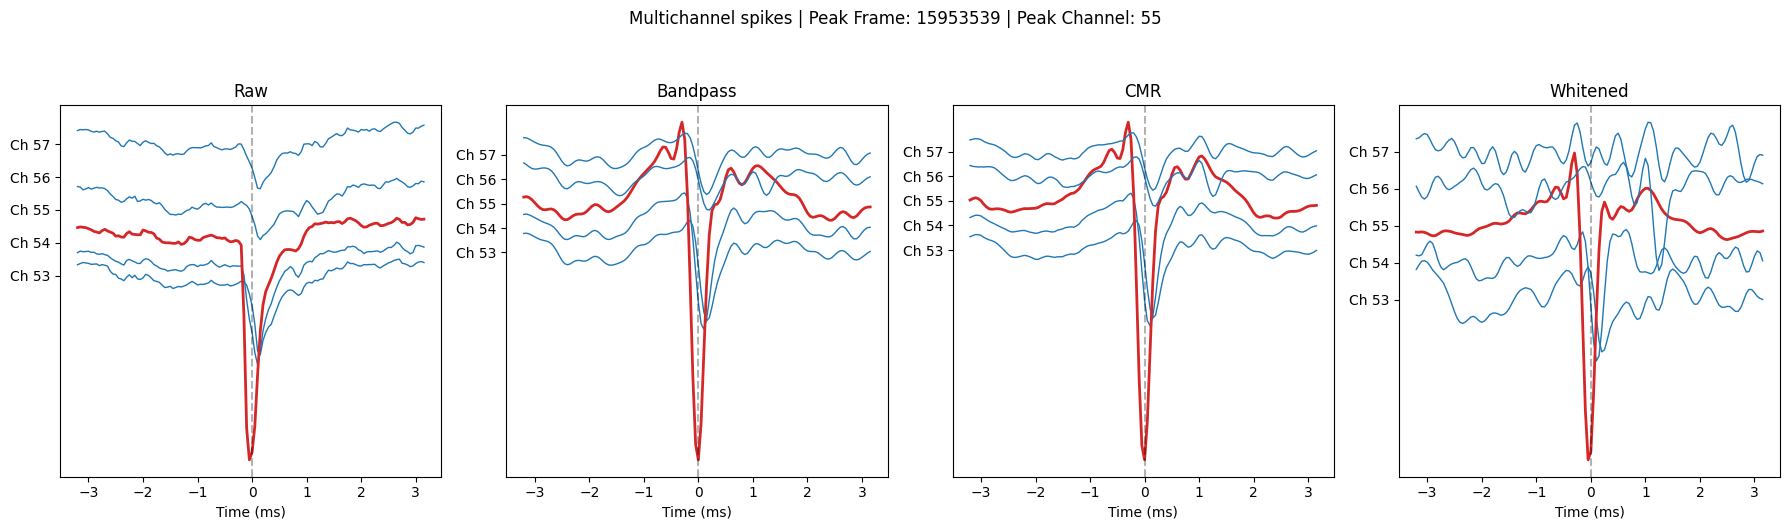

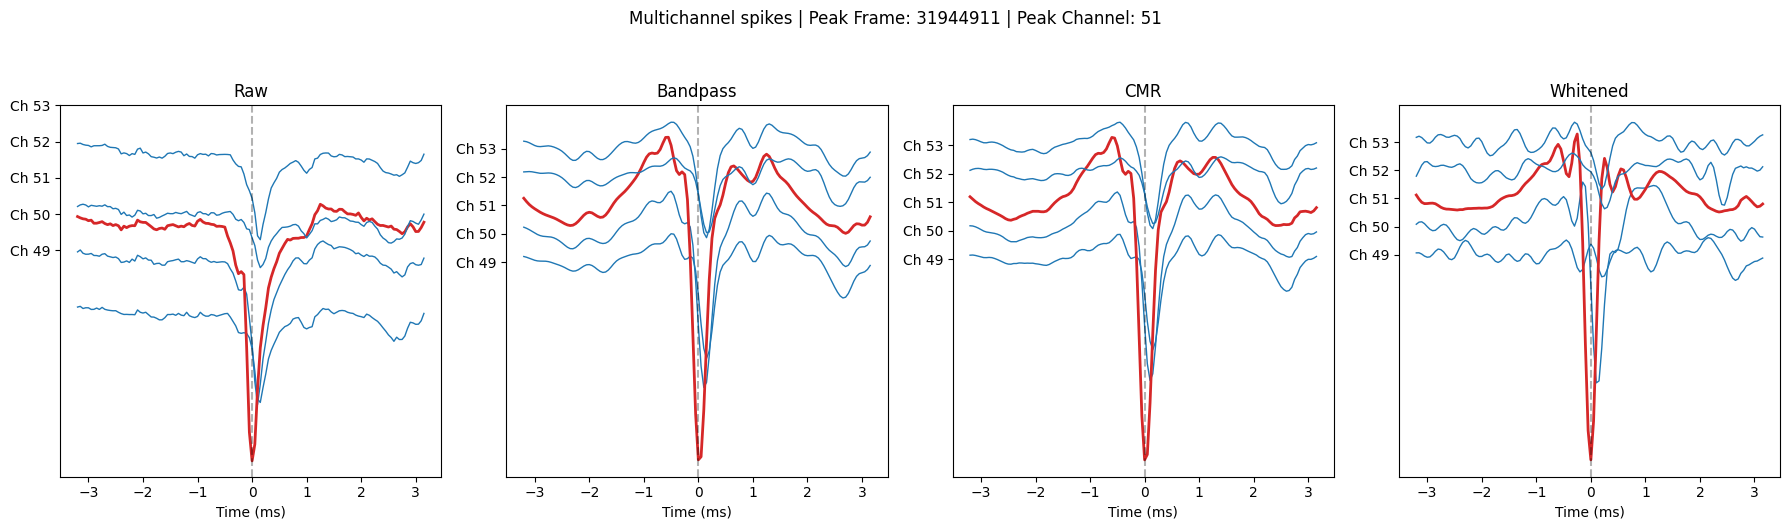


Executing global array voltage trace at recording midpoint...


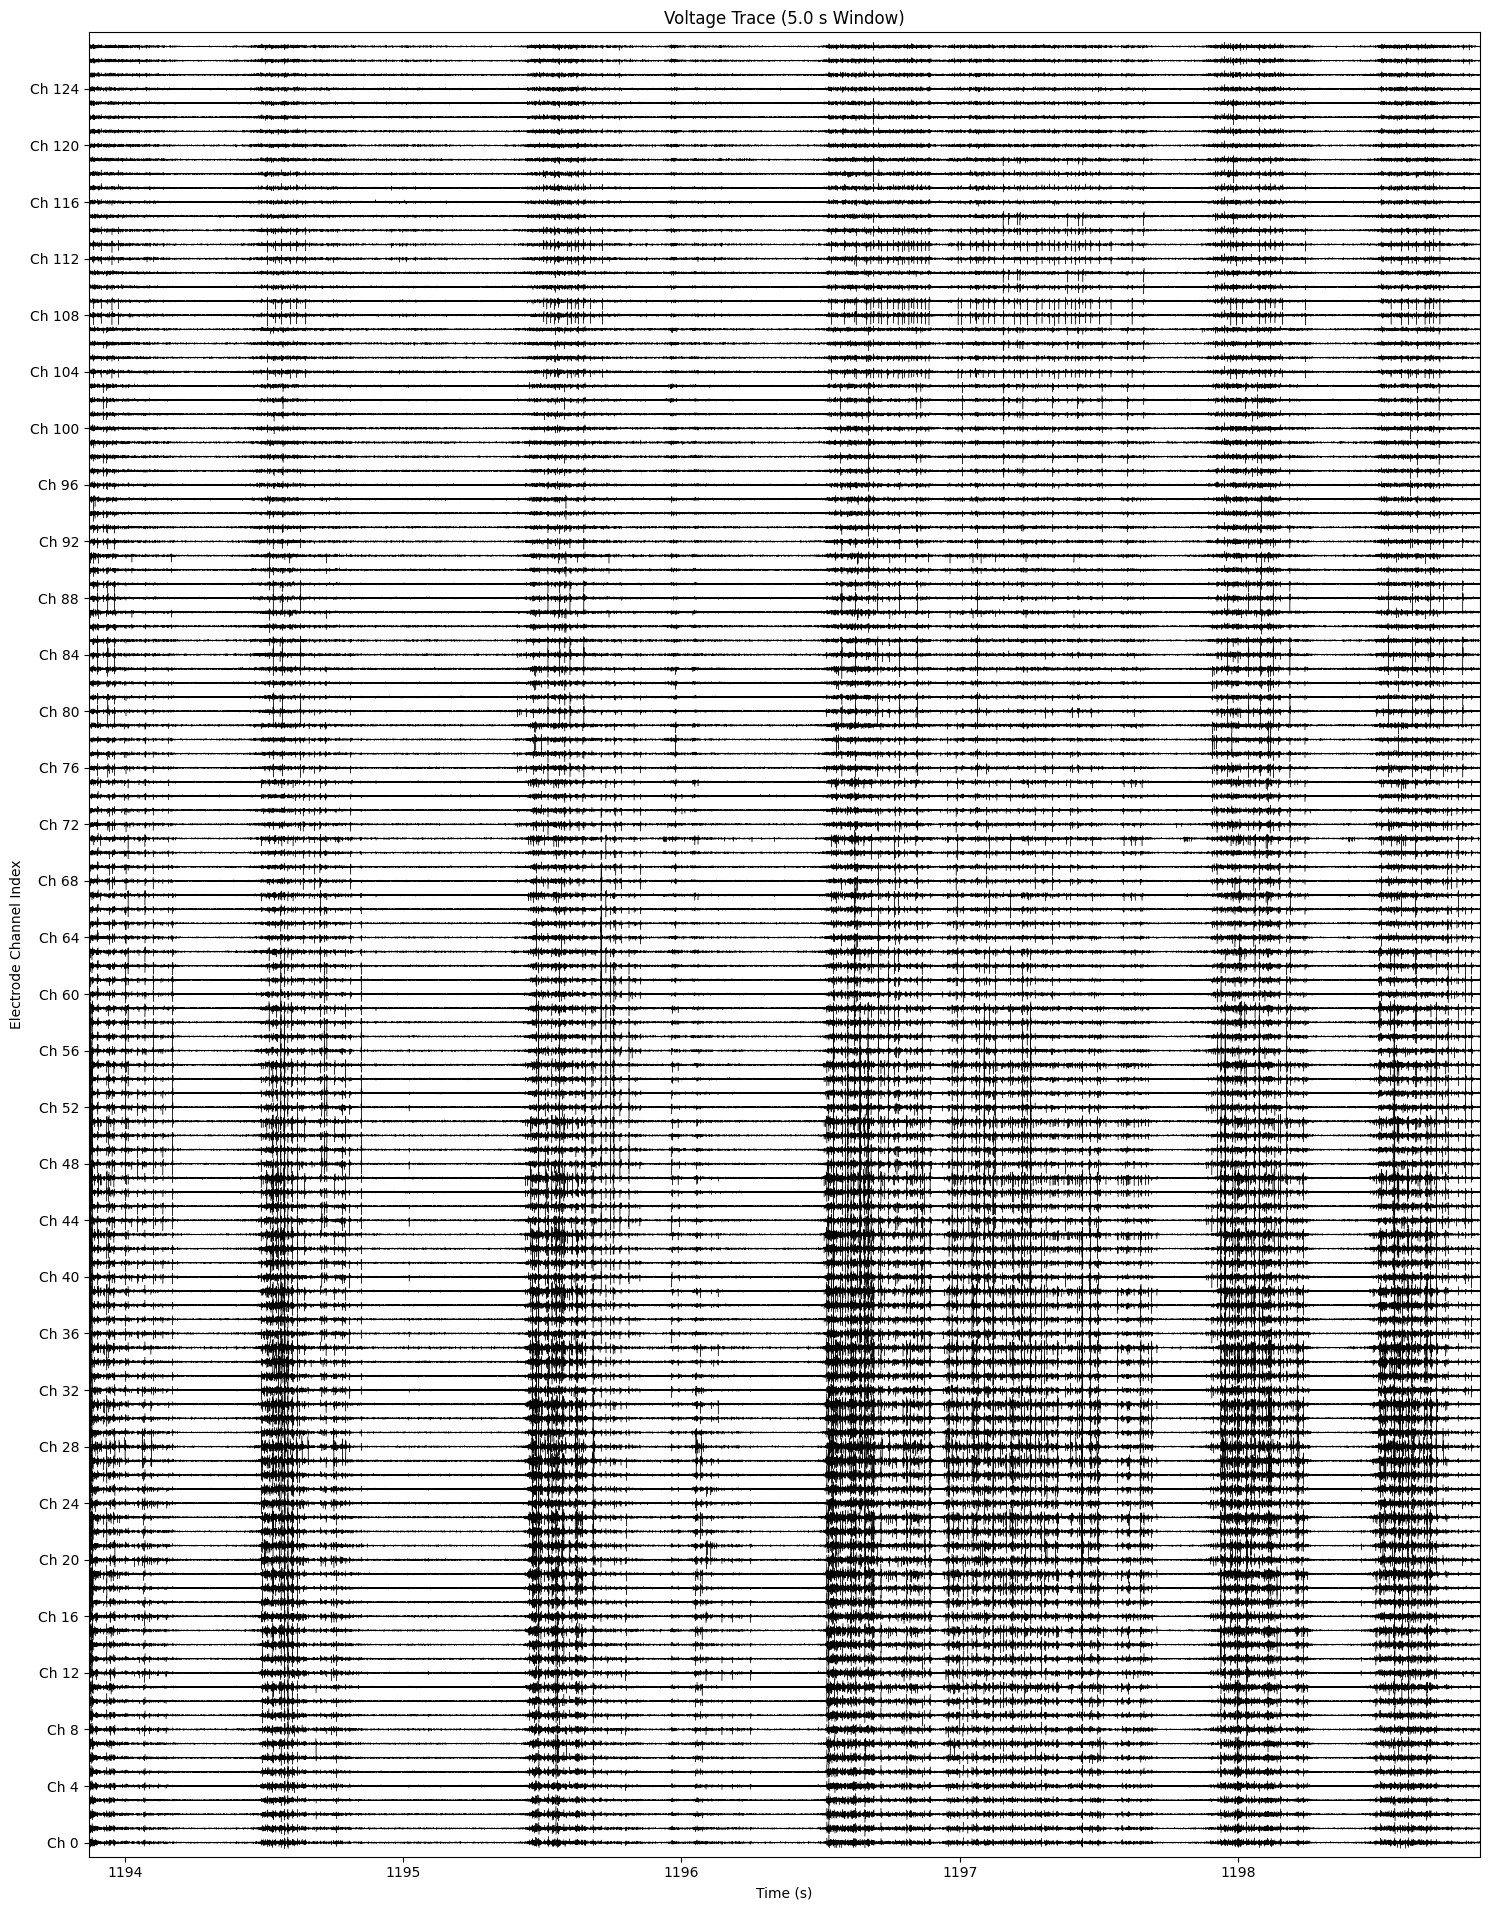

In [4]:
import matplotlib.pyplot as plt
import numpy as np

def plot_multichannel_spike_preprocessing(raw, bp, cmr, whitened, peak_frame, peak_channel, window_size=128, num_neighbors=2):
    """
    Visualizes the morphological evolution of an action potential across preprocessing stages.
    Displays the peak channel and adjacent spatial neighbors with vertical offsets.
    """
    fs = raw.get_sampling_frequency()
    num_channels = raw.get_num_channels()
    
    start_frame = peak_frame - (window_size // 2)
    end_frame = peak_frame + (window_size // 2)
    time_ms = (np.arange(window_size) - (window_size // 2)) * (1000.0 / fs)
    
    # Define spatial boundary indices
    ch_start = max(0, peak_channel - num_neighbors)
    ch_end = min(num_channels, peak_channel + num_neighbors + 1)
    extracted_channels = np.arange(ch_start, ch_end)
    
    fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharey=False)
    
    stages = [
        (raw, "Raw", 200.0),            # 200 uV offset
        (bp, "Bandpass", 100.0),        # 100 uV offset
        (cmr, "CMR", 100.0),            # 100 uV offset
        (whitened, "Whitened", 5.0)     # 5 A.U. offset (variance normalized)
    ]
    
    for i, (rec, title, offset) in enumerate(stages):
        # Extract the spatial block. Raw, BP, and CMR retain physical microvolts.
        if title == "Whitened":
            traces = rec.get_traces(start_frame=start_frame, end_frame=end_frame)[:, ch_start:ch_end]
        else:
            traces = rec.get_traces(start_frame=start_frame, end_frame=end_frame, return_in_uV=True)[:, ch_start:ch_end]
            
        # Plot each channel with a vertical spatial offset
        for j, ch_idx in enumerate(extracted_channels):
            is_peak = (ch_idx == peak_channel)
            color = '#d62728' if is_peak else '#1f77b4'
            linewidth = 2.0 if is_peak else 1.0
            
            axes[i].plot(time_ms, traces[:, j] + (j * offset), color=color, linewidth=linewidth)
            
        axes[i].axvline(x=0, color='black', linestyle='--', alpha=0.3)
        axes[i].set_title(title)
        axes[i].set_xlabel("Time (ms)")
        
        # Configure Y-axis to represent channel indices based on offsets
        axes[i].set_yticks([j * offset for j in range(len(extracted_channels))])
        axes[i].set_yticklabels([f"Ch {ch}" for ch in extracted_channels])
        
    plt.suptitle(f"Multichannel spikes | Peak Frame: {peak_frame} | Peak Channel: {peak_channel}", y=1.05)
    plt.tight_layout()
    plt.show()


def plot_all_channels_snippet(recording, start_frame, duration_sec=5.0, offset_uv=150.0):
    """
    Visualizes continuous microvolt fluctuations across the entire electrode array.
    """
    fs = recording.get_sampling_frequency()
    num_channels = recording.get_num_channels()
    end_frame = start_frame + int(duration_sec * fs)
    
    time_sec = np.arange(start_frame, end_frame) / fs
    
    # Extract matrix in physical microvolts
    traces = recording.get_traces(start_frame=start_frame, end_frame=end_frame, return_in_uV=True)
    
    # Scale figure height dynamically based on the number of recording channels
    fig_height = max(10, num_channels * 0.15)
    fig, ax = plt.subplots(figsize=(15, fig_height))
    
    for ch in range(num_channels):
        ax.plot(time_sec, traces[:, ch] + (ch * offset_uv), color='black', linewidth=0.3)
        
    ax.set_title(f"Voltage Trace ({duration_sec} s Window)")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Electrode Channel Index")
    
    # Subsample Y-axis labels for readability if channel count exceeds 32
    step = max(1, num_channels // 32)
    ax.set_yticks([ch * offset_uv for ch in range(0, num_channels, step)])
    ax.set_yticklabels([f"Ch {ch}" for ch in range(0, num_channels, step)])
    
    # Set plot bounds to eliminate vertical whitespace
    ax.set_ylim(-offset_uv, num_channels * offset_uv)
    ax.set_xlim(time_sec[0], time_sec[-1])
    
    plt.tight_layout()
    plt.show()
# 1. Distributed Multichannel Spike Analysis
print("Executing spatial neighborhood analysis on distributed events...")
total_frames = recording_cmr.get_num_frames()
fs = recording_cmr.get_sampling_frequency()

num_spikes_to_visualize = 3
segment_length = total_frames // num_spikes_to_visualize

for i in range(num_spikes_to_visualize):
    search_start = i * segment_length
    search_end = min(search_start + int(5.0 * fs), total_frames)
    
    # Locate maximum negative voltage deflection in the search window
    cmr_search_chunk = recording_cmr.get_traces(start_frame=search_start, end_frame=search_end, return_in_uV=True)
    flat_peak_idx = np.argmin(cmr_search_chunk)
    peak_frame_local, peak_channel = np.unravel_index(flat_peak_idx, cmr_search_chunk.shape)
    
    absolute_peak_frame = search_start + peak_frame_local
    
    plot_multichannel_spike_preprocessing(
        raw=recording,
        bp=recording_bp,
        cmr=recording_cmr,
        whitened=recording_preprocessed,
        peak_frame=absolute_peak_frame,
        peak_channel=peak_channel,
        window_size=128,
        num_neighbors=2  # Extracts 5 total channels (peak ± 2)
    )

# 2. Global Recording Midpoint Analysis
print("\nExecuting global array voltage trace at recording midpoint...")
midpoint_frame = total_frames // 2
five_sec_frames = int(5.0 * fs)
snippet_start = max(0, midpoint_frame - (five_sec_frames // 2))

# Execute on CMR to retain biological voltage limits
plot_all_channels_snippet(
    recording=recording_cmr,
    start_frame=snippet_start,
    duration_sec=5.0,
    offset_uv=150.0  # Adjust offset if traces overlap excessively
)

Range: -9288 4470

CMR statistics
{'total_values': 6125414400, 'mean': np.float64(-4.210077252405976), 'std': np.float64(723.2112735694375), 'min': np.int16(-9288), 'max': np.int16(4470)}
Range: -154.85638 54.10973

Whitened statistics
{'total_values': 6125414400, 'mean': np.float64(-0.004294662551194165), 'std': np.float64(1.2147082728607903), 'min': np.float32(-154.85638), 'max': np.float32(54.10973)}


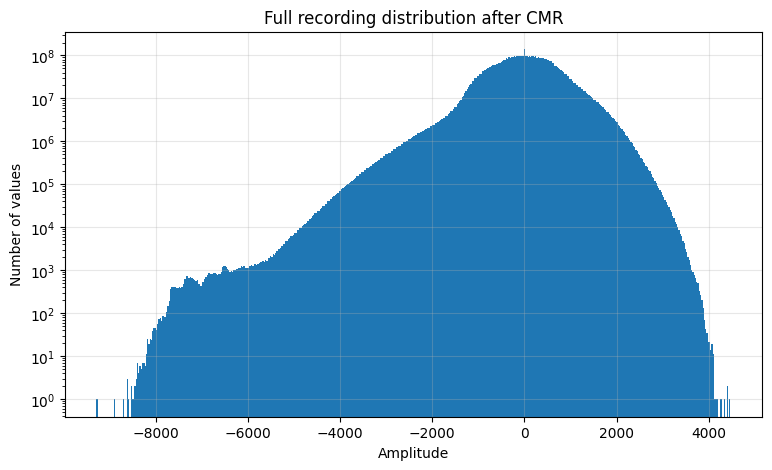

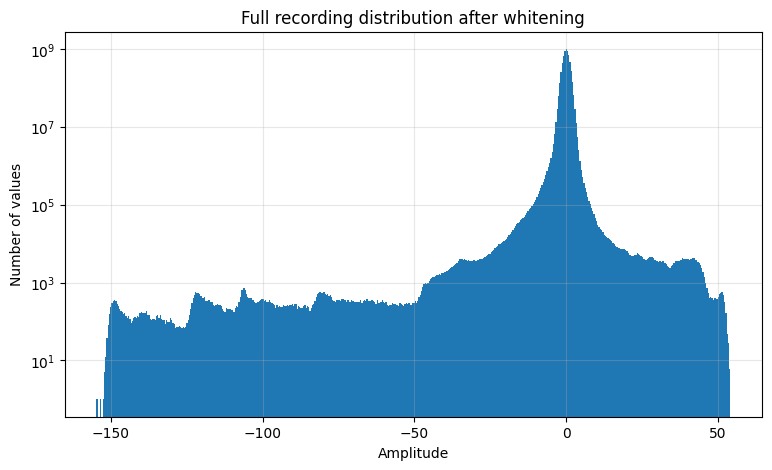

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import spikeinterface.full as si


recording = si.read_nwb_recording(
    "Rat01_Insertion2_Depth2.nwb"
)


# preprocessing
cmr_recording = si.common_reference(
    recording,
    reference="global"
)

whitened_recording = si.whiten(cmr_recording, dtype="float32")



def full_recording_histogram(recording, bins=500, chunk_size=100000):

    num_samples = recording.get_num_samples()

    # ---------------------------------
    # First pass: find global min/max
    # ---------------------------------
    global_min = np.inf
    global_max = -np.inf

    for start in range(0, num_samples, chunk_size):

        end = min(start + chunk_size, num_samples)

        chunk = recording.get_traces(
            start_frame=start,
            end_frame=end
        )

        global_min = min(global_min, chunk.min())
        global_max = max(global_max, chunk.max())


    print("Range:", global_min, global_max)


    # ---------------------------------
    # Second pass: calculate histogram
    # ---------------------------------
    hist = np.zeros(bins, dtype=np.int64)

    bin_edges = np.linspace(
        global_min,
        global_max,
        bins + 1
    )


    total_values = 0
    sum_values = 0
    sum_squared = 0


    for start in range(0, num_samples, chunk_size):

        end = min(start + chunk_size, num_samples)

        chunk = recording.get_traces(
            start_frame=start,
            end_frame=end
        ).astype(np.float64)


        flat = chunk.ravel()


        # histogram
        current_hist, _ = np.histogram(
            flat,
            bins=bin_edges
        )

        hist += current_hist


        # statistics
        total_values += flat.size
        sum_values += flat.sum()
        sum_squared += np.sum(flat**2)

    mean = sum_values / total_values
    std = np.sqrt(
        sum_squared / total_values - mean**2
    )

    return hist, bin_edges, {
        "total_values": total_values,
        "mean": mean,
        "std": std,
        "min": global_min,
        "max": global_max
    }



# --------------------------
# CMR
# --------------------------

cmr_hist, cmr_edges, cmr_stats = full_recording_histogram(
    cmr_recording
)

print("\nCMR statistics")
print(cmr_stats)



# --------------------------
# Whitening
# --------------------------

white_hist, white_edges, white_stats = full_recording_histogram(
    whitened_recording
)

print("\nWhitened statistics")
print(white_stats)



# --------------------------
# Plot
# --------------------------

plt.figure(figsize=(9,5))

plt.bar(
    cmr_edges[:-1],
    cmr_hist,
    width=np.diff(cmr_edges),
    align="edge"
)

plt.xlabel("Amplitude")
plt.ylabel("Number of values")
plt.title("Full recording distribution after CMR")
plt.yscale("log")
plt.grid(alpha=0.3)

plt.show()



plt.figure(figsize=(9,5))

plt.bar(
    white_edges[:-1],
    white_hist,
    width=np.diff(white_edges),
    align="edge"
)

plt.xlabel("Amplitude")
plt.ylabel("Number of values")
plt.title("Full recording distribution after whitening")
plt.yscale("log")
plt.grid(alpha=0.3)

plt.show()